# Downloading & Inspecting Geospatial Inputs

The `spatial_anonymization` package can automatically download the geospatial layers
needed for survey coordinate displacement. This notebook demonstrates how to:

1. **Download admin boundaries** from [geoBoundaries](https://www.geoboundaries.org/) (with GADM fallback)
2. **Auto-discover the most granular admin level** available for a country
3. **Download population rasters** from [WorldPop](https://www.worldpop.org/)
4. **Download water bodies** from [OpenStreetMap](https://www.openstreetmap.org/) via the Overpass API
5. **Inspect and visualize** each layer

> **Requirements:** An internet connection is needed to run the download cells.
> All downloads use `verify=False` for SSL, so they work behind corporate proxies.

---

## 1. Python Setup

In [ ]:
%load_ext autoreload
%autoreload 2

In [2]:
import warnings
warnings.filterwarnings("ignore", message="Unverified HTTPS request")

from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

from spatial_anonymization.data.inputs_manager import InputsManager

## 2. Configuration

Set the country ISO3 code and a local directory where downloaded files will be cached.
Subsequent runs will reuse cached files instead of re-downloading.

| Parameter | Description |
| --- | --- |
| `COUNTRY_ISO3` | ISO 3166-1 alpha-3 country code (e.g., `MWI`, `ETH`, `TZA`, `NGA`) |
| `ADMIN_LEVEL` | Administrative level: 0 = country, 1 = region, 2 = district, 3+ = sub-district |
| `DOWNLOAD_DIR` | Local folder for cached downloads |

In [5]:
# ===================================
# WORKING DIRECTORY
# ===================================
DIR_WORK_BASE = Path.cwd().parents[0]  # Set to the parent directory of the current working directory
DIR_DATA = DIR_WORK_BASE / "data/mwi2"
DOWNLOAD_DIR = DIR_DATA / "geospatial_inputs"
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

# ======================================
# CONFIGURATION
# ======================================
COUNTRY_ISO3 = "MWI"      # Malawi
ADMIN_LEVEL = 2            # District level

print(f"Country:        {COUNTRY_ISO3}")
print(f"Admin level:    ADM{ADMIN_LEVEL}")
print(f"Download dir:   {DOWNLOAD_DIR.resolve()}")

Country:        MWI
Admin level:    ADM2
Download dir:   /Users/dmatekenya/Library/CloudStorage/OneDrive-WBG/Survey-Geo-Enhancement/git-repos/spatial-anonymization/data/mwi2/geospatial_inputs


## 3. Download Admin Boundaries

Creating an `InputsManager` with `auto_download=True` will automatically download
admin boundaries from **geoBoundaries**. If that source is unavailable, it falls back to **GADM**.

Downloaded files are cached as GeoJSON in `DOWNLOAD_DIR` and reused on subsequent runs.

In [6]:
inputs = InputsManager(
    country_iso3=COUNTRY_ISO3,
    admin_level=ADMIN_LEVEL,
    auto_download=True,
    download_dir=str(DOWNLOAD_DIR),
)

Saved admin boundaries to /Users/dmatekenya/Library/CloudStorage/OneDrive-WBG/Survey-Geo-Enhancement/git-repos/spatial-anonymization/data/mwi2/geospatial_inputs/MWI_admin_level2_geoboundaries.geojson
Successfully downloaded 28 admin boundaries from geoBoundaries


### 3.1 Inspect Admin Boundaries

In [7]:
admin_gdf = inputs.get_admin_gdf()

print(f"Admin level:     ADM{inputs.get_admin_level()}")
print(f"Number of units: {len(admin_gdf)}")
print(f"CRS:             {admin_gdf.crs}")
print(f"Columns:         {list(admin_gdf.columns)}")
print()
admin_gdf.head()

Admin level:     ADM2
Number of units: 28
CRS:             EPSG:4326
Columns:         ['shapeName', 'shapeISO', 'shapeID', 'shapeGroup', 'shapeType', 'geometry']



,shapeName,shapeISO,shapeID,shapeGroup,shapeType,geometry
0,Balaka,,42251766B20450933672567,MWI,ADM2,"POLYGON ((35.28365 -14.77625, 35.28173 -14.777..."
1,Blantyre,,42251766B636776762176,MWI,ADM2,"POLYGON ((34.97696 -15.3521, 34.97618 -15.3515..."
2,Chikwawa,,42251766B28594103932184,MWI,ADM2,"POLYGON ((34.73348 -15.81583, 34.52317 -15.808..."
3,Chiradzulu,,42251766B78568245260433,MWI,ADM2,"POLYGON ((35.12323 -15.85648, 35.12411 -15.856..."
4,Chitipa,,42251766B85605316960959,MWI,ADM2,"POLYGON ((33.6407 -9.60072, 33.63964 -9.6003, ..."


### 3.2 Plot Admin Boundaries

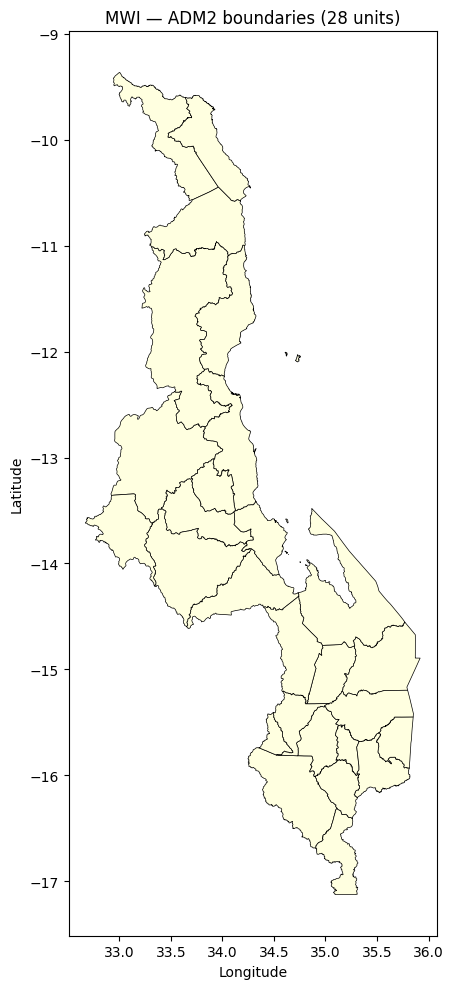

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(8, 10))
admin_gdf.plot(ax=ax, edgecolor="black", facecolor="lightyellow", linewidth=0.5)
ax.set_title(f"{COUNTRY_ISO3} — ADM{ADMIN_LEVEL} boundaries ({len(admin_gdf)} units)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

## 4. Auto-Discover Most Granular Admin Level

If you don't know the finest admin level available for a country, use
`find_most_granular_admin()`. It tries ADM5 → ADM4 → … → ADM0 and returns
the first level that succeeds (checking geoBoundaries, then GADM, at each level).

> This updates `inputs.admin_level` and `inputs.admin_gdf` in place.

In [9]:
granular_gdf = inputs.find_most_granular_admin(max_level=5)

print(f"Most granular level: ADM{inputs.admin_level}")
print(f"Number of units:     {len(granular_gdf)}")

Saved admin boundaries to /Users/dmatekenya/Library/CloudStorage/OneDrive-WBG/Survey-Geo-Enhancement/git-repos/spatial-anonymization/data/mwi2/geospatial_inputs/MWI_admin_level3_geoboundaries.geojson
Successfully downloaded 245 admin boundaries from geoBoundaries
Found most granular admin level: ADM3 (245 features) from geoBoundaries
Most granular level: ADM3
Number of units:     245


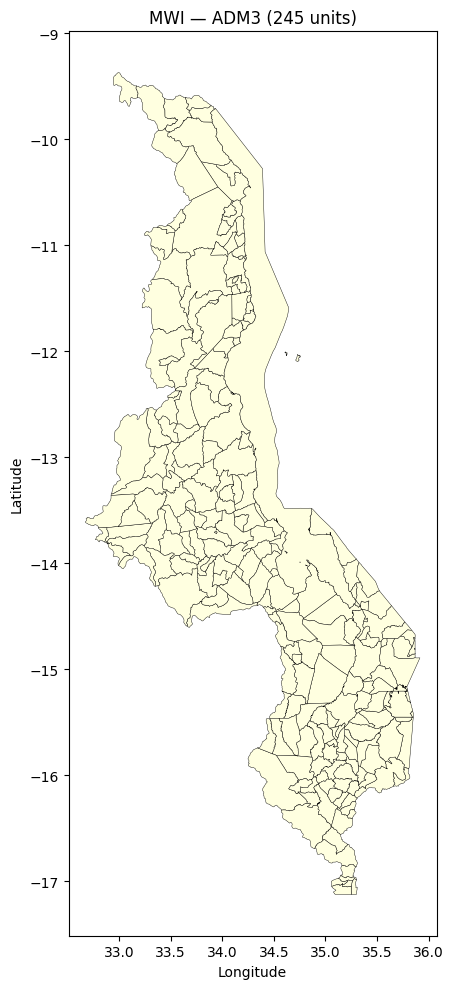

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(8, 10))
granular_gdf.plot(ax=ax, edgecolor="black", facecolor="lightyellow", linewidth=0.3)
ax.set_title(f"{COUNTRY_ISO3} — ADM{inputs.admin_level} ({len(granular_gdf)} units)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

## 5. Download Population Raster

Downloads a WorldPop **constrained population count** raster (100 m resolution).
The raster is used during anonymization to avoid displacing points into unpopulated areas.

| Parameter | Description |
| --- | --- |
| `year` | Population estimate year (2015–2030). Default: 2025 |

In [11]:
raster_path = inputs.download_population_raster(year=2020)

print(f"Raster saved to: {raster_path}")
print(f"File size:        {Path(raster_path).stat().st_size / 1024 / 1024:.1f} MB")

Successfully downloaded WorldPop raster to /Users/dmatekenya/Library/CloudStorage/OneDrive-WBG/Survey-Geo-Enhancement/git-repos/spatial-anonymization/data/mwi2/geospatial_inputs/mwi_worldpop_2020.tif
Raster saved to: /Users/dmatekenya/Library/CloudStorage/OneDrive-WBG/Survey-Geo-Enhancement/git-repos/spatial-anonymization/data/mwi2/geospatial_inputs/mwi_worldpop_2020.tif
File size:        27.2 MB


### 5.1 Inspect Population Raster

Dimensions:   3895 x 9314 pixels
Bands:        1
CRS:          EPSG:4326
Resolution:   0.000833° x 0.000833°
Bounds:       BoundingBox(left=32.67333248264, bottom=-17.129999595480015, right=35.91916580299, top=-9.368332959860016)



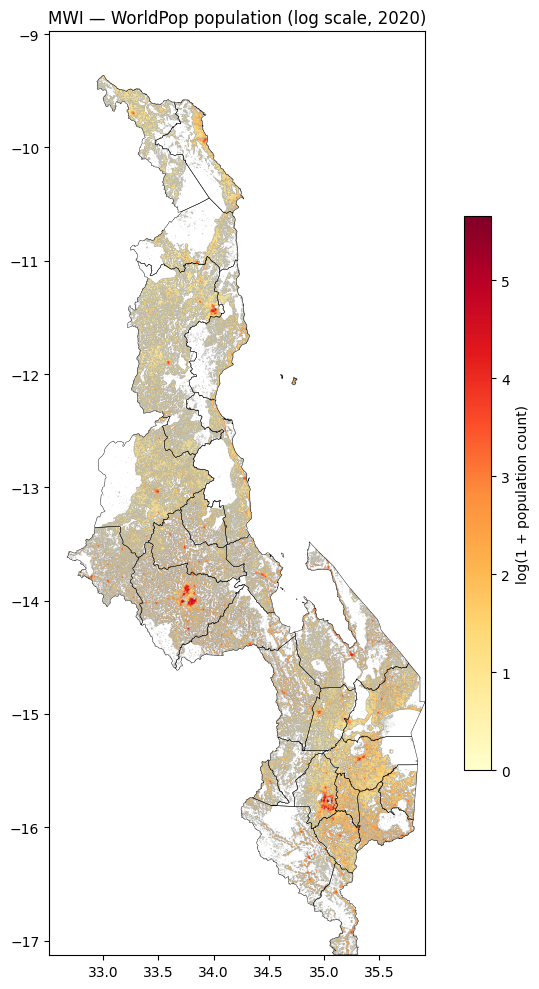

In [12]:
import rasterio
from rasterio.plot import show
import numpy as np

with rasterio.open(raster_path) as src:
    print(f"Dimensions:   {src.width} x {src.height} pixels")
    print(f"Bands:        {src.count}")
    print(f"CRS:          {src.crs}")
    print(f"Resolution:   {src.res[0]:.6f}° x {src.res[1]:.6f}°")
    print(f"Bounds:       {src.bounds}")
    print()

    # Read and display
    data = src.read(1)
    # Mask nodata for display
    nodata = src.nodata
    if nodata is not None:
        data = np.where(data == nodata, np.nan, data)

    fig, ax = plt.subplots(1, 1, figsize=(8, 10))
    im = ax.imshow(
        np.log1p(data),  # log scale for better contrast
        cmap="YlOrRd",
        extent=[src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top],
    )
    admin_gdf.boundary.plot(ax=ax, edgecolor="black", linewidth=0.3)
    ax.set_title(f"{COUNTRY_ISO3} — WorldPop population (log scale, {2020})")
    plt.colorbar(im, ax=ax, label="log(1 + population count)", shrink=0.6)
    plt.tight_layout()
    plt.show()

## 6. Download Water Bodies

Downloads water features (lakes, rivers, streams) from OpenStreetMap via the Overpass API.
Water bodies are used during anonymization to prevent displacing points into water.

> **Note:** The Overpass API may timeout for large countries. If this fails, you can
> provide your own water body shapefile via the `water_gdf` parameter.

In [ ]:
water_gdf = inputs.download_water_bodies()

if water_gdf is not None:
    print(f"Water features:  {len(water_gdf)}")
    print(f"Geometry types:  {water_gdf.geometry.type.value_counts().to_dict()}")
    print(f"CRS:             {water_gdf.crs}")
else:
    print("No water bodies downloaded (API may have timed out).")

In [ ]:
if water_gdf is not None:
    fig, ax = plt.subplots(1, 1, figsize=(8, 10))
    admin_gdf.plot(ax=ax, edgecolor="gray", facecolor="lightyellow", linewidth=0.3)
    water_gdf.plot(ax=ax, color="steelblue", linewidth=0.5, alpha=0.7)
    ax.set_title(f"{COUNTRY_ISO3} — Water bodies ({len(water_gdf)} features)")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    plt.tight_layout()
    plt.show()

## 7. Summary of Available Inputs

Use the `has_*` methods to check which layers are loaded.

In [ ]:
print("=" * 45)
print(f" Input Summary for {COUNTRY_ISO3}")
print("=" * 45)
print(f"  Admin boundaries:   {'Yes' if inputs.has_admin() else 'No'}")
print(f"  Admin level:        ADM{inputs.admin_level}")
print(f"  Population raster:  {'Yes' if inputs.has_population() else 'No'}")
print(f"  Water bodies:       {'Yes' if inputs.has_water() else 'No'}")
print(f"  UTM EPSG:           {inputs.get_utm_epsg()}")
print("=" * 45)

## 8. Using Your Own Data

You can skip the automatic downloads entirely by providing your own GeoDataFrames
and raster paths:

```python
import geopandas as gpd

my_admin = gpd.read_file("path/to/my_admin_boundaries.shp")
my_water = gpd.read_file("path/to/my_water_bodies.shp")

inputs = InputsManager(
    country_iso3="MWI",
    admin_gdf=my_admin,                          # your own boundaries
    admin_level=3,
    water_gdf=my_water,                          # your own water layer
    population_raster_path="path/to/pop.tif",    # your own raster
    auto_download=False,                          # no downloads needed
)
```

> When `admin_gdf` is provided, the package uses it directly — no download is attempted,
> even if `auto_download=True`.

---

**Next steps:** Once you have your inputs ready, head to the
[Getting Started](getting_started.ipynb) notebook to run the full anonymization workflow.